<a href="https://colab.research.google.com/github/natitedros/WAVN-agentic-navigation/blob/main/poc_tests/vint_test_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 4: Testing ViNT on a TartanGround route

ViNT gets two things:
- **What the robot sees now**: the current camera frame plus the 5 frames before it.
- **Where it wants to go**: one goal image.

It returns two things:
- **Distance**: roughly how many steps away the goal is (0 = here, 20 = far away or not reachable).
- **Waypoints**: the next 5 positions the robot should drive to, in the robot's own frame (x = forward, y = left).

This notebook checks three things on a recorded TartanGround route, where we know the real answer from the camera positions:
1. **Distance test**: does the predicted distance grow as the goal gets further away?
2. **Direction test**: do the predicted waypoints turn the same way the robot really turned?
3. **Far-goal test**: does ViNT say "far / not reachable" for goal images from a distant part of the route?

**Runtime:** a T4 GPU is faster, but ViNT is small and also runs on CPU.

Edit only the lines marked `# <-- EDIT`.

## 1. Install ViNT's code

In [1]:
!git clone -q https://github.com/robodhruv/visualnav-transformer.git /content/visualnav-transformer 2>/dev/null || echo "already cloned"
!pip install -q efficientnet_pytorch warmup_scheduler gdown

import sys
sys.path.insert(0, "/content/visualnav-transformer/train")   # makes `vint_train` importable

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
Using: cuda Tesla T4


## 2. Get the pretrained ViNT weights

The authors share the weights in a Google Drive folder. The cell below tries to download `vint.pth` automatically.

If it fails (Google Drive sometimes blocks automatic downloads), do it by hand:
1. Open https://drive.google.com/drive/folders/1a9yWR2iooXFAqjQHetz263--4_2FFggg
2. Download `vint.pth` and upload it to your own Drive.
3. Set `WEIGHTS_PATH` below to where you put it.

In [2]:
import os, glob
from google.colab import drive
drive.mount('/content/drive')

WEIGHTS_PATH = "/content/drive/MyDrive/tartanground/vint_test/vint_weights/vint.pth"
RESULTS_FOLDER = "/content/drive/MyDrive/tartanground/vint_test/vint_results"
os.makedirs(RESULTS_FOLDER, exist_ok=True)

if not os.path.exists(WEIGHTS_PATH):
    print("Downloading the shared weights folder...")
    !gdown -q --folder https://drive.google.com/drive/folders/1a9yWR2iooXFAqjQHetz263--4_2FFggg -O /content/vint_weights
    found = glob.glob("/content/vint_weights/**/vint.pth", recursive=True)
    if found:
        WEIGHTS_PATH = found[0]

if os.path.exists(WEIGHTS_PATH):
    print(f"Weights: {WEIGHTS_PATH} ({os.path.getsize(WEIGHTS_PATH) / 1e6:.0f} MB)")
else:
    print("Could not get vint.pth automatically. Follow the manual steps above, then run this cell again.")

Mounted at /content/drive
Weights: /content/drive/MyDrive/tartanground/vint_test/vint_weights/vint.pth (430 MB)


## 3. Load ViNT

The weights file was saved together with some training objects ViNT doesn't need for predictions. If one of those can't be loaded, the cell skips it and says so; that's fine.

In [3]:
import pickle, types, yaml
from vint_train.models.vint.vint import ViNT

with open("/content/visualnav-transformer/train/config/vint.yaml") as f:
    cfg = yaml.safe_load(f)

CONTEXT_SIZE = cfg["context_size"]          # 5 past frames + the current one
IMAGE_SIZE = tuple(cfg["image_size"])       # (width, height) = (85, 64)
MAX_DIST = cfg["distance"]["max_dist_cat"]  # 20 = "far / not reachable"

model = ViNT(
    context_size=cfg["context_size"],
    len_traj_pred=cfg["len_traj_pred"],
    learn_angle=cfg["learn_angle"],
    obs_encoder=cfg["obs_encoder"],
    obs_encoding_size=cfg["obs_encoding_size"],
    late_fusion=cfg["late_fusion"],
    mha_num_attention_heads=cfg["mha_num_attention_heads"],
    mha_num_attention_layers=cfg["mha_num_attention_layers"],
    mha_ff_dim_factor=cfg["mha_ff_dim_factor"],
)

# Load the checkpoint, skipping any saved training object whose code isn't installed.
skipped = []
class _Placeholder:
    def __init__(self, *args, **kwargs): pass
    def __setstate__(self, state): pass

class _ForgivingUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        try:
            return super().find_class(module, name)
        except (ModuleNotFoundError, AttributeError):
            skipped.append(f"{module}.{name}")
            return _Placeholder

forgiving_pickle = types.ModuleType("forgiving_pickle")
forgiving_pickle.Unpickler = _ForgivingUnpickler
forgiving_pickle.load = lambda f, **kw: _ForgivingUnpickler(f, **kw).load()

checkpoint = torch.load(WEIGHTS_PATH, map_location="cpu", weights_only=False, pickle_module=forgiving_pickle)
if skipped:
    print("Skipped (not needed for predictions):", sorted(set(skipped)))

saved = checkpoint["model"] if isinstance(checkpoint, dict) and "model" in checkpoint else checkpoint
saved = getattr(saved, "module", saved)          # unwrap multi-GPU wrapper
state_dict = saved.state_dict() if hasattr(saved, "state_dict") else saved
if not isinstance(state_dict, dict):
    raise RuntimeError("The saved model itself could not be loaded. Skipped: " + str(sorted(set(skipped))))

result = model.load_state_dict(state_dict, strict=False)
print(f"Missing weights: {len(result.missing_keys)}   Unexpected weights: {len(result.unexpected_keys)}")
if result.missing_keys:
    print("WARNING: some weights are missing, predictions will be wrong:", result.missing_keys[:5])

model = model.to(device).eval()
print(f"ViNT loaded: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

/content/visualnav-transformer/train/vint_train/models/vint/self_attention.py:32: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.sa_decoder = nn.TransformerEncoder(self.sa_layer, num_layers=num_layers)


Missing weights: 0   Unexpected weights: 0
ViNT loaded: 29.7M parameters


## 4. Get one TartanGround route

Choose a route. Robot types and their route names:
- `diff` (wheeled, always drives forward): routes `P1000`, `P1001`, ...
- `omni` (can also drive sideways): routes `P0000`, `P0001`, ...
- `anymal` (legged): routes `P2000`, `P2001`, ...

**Use `diff` if your environment has it.** ViNT learned from robots that drive forward with a forward camera. An `omni` robot sliding sideways will confuse it. Check which `Data_...` folders exist for your environment in the Hugging Face file browser.

This downloads only the front camera's photos plus the small metadata file (about 400 MB) to Colab's disk, not your Drive.

In [4]:
ENV = "Antiquity3D"   # <-- EDIT
VERSION = "diff"            # <-- EDIT: "diff" or "omni"
TRAJ = "P1000"              # <-- EDIT: P1000 for diff, P0000 for omni
CAMERA = "lcam_front"

DRIVE_ROUTE = f"/content/drive/MyDrive/tartanground/{ENV}/Data_{VERSION}/{TRAJ}"
DATA_ROOT = "/content/tartanground"
LOCAL_ROUTE = f"{DATA_ROOT}/{ENV}/Data_{VERSION}/{TRAJ}"

import shutil, zipfile
assert os.path.isdir(DRIVE_ROUTE), f"Folder not found: {DRIVE_ROUTE}"
os.makedirs(LOCAL_ROUTE, exist_ok=True)

for name in sorted(os.listdir(DRIVE_ROUTE)):
    src = os.path.join(DRIVE_ROUTE, name)
    if name.endswith(".zip"):
        print("Unzipping", name)
        with zipfile.ZipFile(src) as z:
            z.extractall(LOCAL_ROUTE)
    elif os.path.isdir(src):
        print("Copying folder", name)
        shutil.copytree(src, os.path.join(LOCAL_ROUTE, name), dirs_exist_ok=True)
    else:
        print("Copying file", name)
        shutil.copy(src, LOCAL_ROUTE)

print("Now in the route folder:", os.listdir(LOCAL_ROUTE))

Copying folder image_lcam_front
Unzipping metadata.zip
Now in the route folder: ['pose_rcam_back.txt', 'pose_lcam_left.txt', 'pose_lcam_front.txt', 'pose_rcam_top.txt', 'pose_lcam_bottom.txt', 'pose_lcam_top.txt', 'P1000_metadata.json', 'pose_rcam_left.txt', 'pose_rcam_front.txt', 'pose_lcam_right.txt', 'image_lcam_front', 'pose_rcam_bottom.txt', 'pose_lcam_back.txt', 'pose_rcam_right.txt', 'collection_config.yaml']


## 5. Find the photos and the camera positions

The camera positions are a text file with one line per frame. We don't know for sure which zip it comes in, so the cell searches the route folder for it.

In [5]:
import numpy as np
from collections import Counter

# Every photo under DATA_ROOT that belongs to this environment, route and camera
photos = [p for p in glob.glob(f"{DATA_ROOT}/**/*", recursive=True)
          if p.lower().endswith((".png", ".jpg"))
          and f"image_{CAMERA}" in p and f"/{TRAJ}/" in p and ENV in p]

if not photos:
    print(f"No photos found under {DATA_ROOT}. Here's what is there:")
    !find {DATA_ROOT} -maxdepth 7 | head -60
    raise FileNotFoundError("Send this listing to Claude.")

# Use the folder that holds the most photos (skips empty leftover folders)
IMAGE_DIR, count = Counter(os.path.dirname(p) for p in photos).most_common(1)[0]
frame_files = sorted(p for p in photos if os.path.dirname(p) == IMAGE_DIR)
ROUTE_DIR = IMAGE_DIR.split(f"/{TRAJ}/")[0] + f"/{TRAJ}"

poses_found = [p for p in glob.glob(f"{DATA_ROOT}/**/pose_{CAMERA}.txt", recursive=True)
               if f"/{TRAJ}/" in p and ENV in p]
POSE_FILE = poses_found[0] if poses_found else None

print("Photos folder:", IMAGE_DIR)
print(f"Frames: {len(frame_files)}  (first: {os.path.basename(frame_files[0])})")
print("Positions file:", POSE_FILE or "NOT FOUND (direction test will be skipped)")

Photos folder: /content/tartanground/Antiquity3D/Data_diff/P1000/image_lcam_front/image_lcam_front
Frames: 2789  (first: 000000_lcam_front.png)
Positions file: /content/tartanground/Antiquity3D/Data_diff/P1000/pose_lcam_front.txt


## 6. Convert positions to the robot's point of view, and pick the frames

ViNT learned from frames about 0.25 m of driving apart. The robot's speed changes along a route, so instead of taking every 2nd or 3rd frame, this cell keeps **the frame closest to every `TARGET_SPACING_M` of driving** (0.25 m, 0.50 m, 0.75 m, ...). That way "1 frame ahead" always means about the same real distance.

When the robot turns on the spot without moving, no new frame is kept until it starts driving again.

Positions are stored as `x y z` plus a 4-number rotation, in a north-east-down frame. The cell converts them so that, for the robot at any moment, **x = forward and y = left**, the same as ViNT's waypoints.

In [6]:
TARGET_SPACING_M = 0.25   # meters of driving between the frames ViNT sees
FLIP_LEFT_RIGHT = False   # set True only if the turn check in section 7 says left/right are swapped
MAX_FRAMES = 1500         # cap so the tests stay quick

positions_xy = yaw = TRAVELED = None
if POSE_FILE:
    poses = np.loadtxt(POSE_FILE)
    if len(poses) != len(frame_files):
        print(f"Note: {len(poses)} positions vs {len(frame_files)} frames; using the shorter length")
    n = min(len(poses), len(frame_files))
    poses, frame_files = poses[:n], frame_files[:n]

    north, east = poses[:, 0], poses[:, 1]
    qx, qy, qz, qw = poses[:, 3], poses[:, 4], poses[:, 5], poses[:, 6]
    heading_ned = np.arctan2(2 * (qw * qz + qx * qy), 1 - 2 * (qy ** 2 + qz ** 2))   # clockwise from north

    # North-east-down -> x forward / y left convention (counter-clockwise angles)
    positions_xy = np.stack([north, -east], axis=1)
    yaw = -heading_ned
    if FLIP_LEFT_RIGHT:
        positions_xy[:, 1] *= -1
        yaw = -yaw

    # Distance driven since the start of the route, for every recorded frame
    step_m = np.linalg.norm(np.diff(positions_xy, axis=0), axis=1)
    TRAVELED = np.r_[0.0, np.cumsum(step_m)]

    # Keep the recorded frame closest to every 0.25 m, 0.50 m, 0.75 m, ... of driving.
    # (If the robot moves more than 0.25 m between two recorded frames, the gap there is larger.)
    marks = np.arange(0, TRAVELED[-1], TARGET_SPACING_M)
    j = np.clip(np.searchsorted(TRAVELED, marks), 1, len(TRAVELED) - 1)
    nearest = np.where(np.abs(TRAVELED[j - 1] - marks) <= np.abs(TRAVELED[j] - marks), j - 1, j)
    idx = np.unique(nearest)[:MAX_FRAMES]
    print(f"Route length: {TRAVELED[-1]:.0f} m   Recorded frames: {len(frame_files)}")
    print(f"Speed varies: movement per recorded frame ranges from {np.percentile(step_m, 5):.2f} "
          f"to {np.percentile(step_m, 95):.2f} m (5th to 95th percentile)")
else:
    idx = np.arange(0, len(frame_files), 3)[:MAX_FRAMES]   # 10 Hz -> about 3 per second
    print("No positions file: using every 3rd frame (distances will be less reliable)")

N = len(idx)
print(f"Frames used: {N}")

if positions_xy is not None:
    P, Y = positions_xy[idx], yaw[idx]
    gaps = np.linalg.norm(np.diff(P, axis=0), axis=1)
    SPACING = np.mean(gaps)
    print(f"Spacing between used frames: average {SPACING:.2f} m "
          f"(5th to 95th percentile: {np.percentile(gaps, 5):.2f} to {np.percentile(gaps, 95):.2f} m)")


def to_local(points, origin, heading):
    # World points -> robot frame at `origin` facing `heading` (x forward, y left).
    d = points - origin
    c, s = np.cos(heading), np.sin(heading)
    return np.stack([d[..., 0] * c + d[..., 1] * s, -d[..., 0] * s + d[..., 1] * c], axis=-1)


def true_waypoints(t, n=5):
    # The real next n positions after used-frame t, in the robot's frame, in "frame spacing" units.
    future = P[t + 1: t + 1 + n]
    return to_local(future, P[t], Y[t]) / SPACING


def path_length_m(a, b):
    # Meters driven between used frames a and b (None if there's no positions file).
    return None if TRAVELED is None else TRAVELED[idx[b]] - TRAVELED[idx[a]]

Note: 2788 positions vs 2789 frames; using the shorter length
Route length: 293 m   Recorded frames: 2788
Speed varies: movement per recorded frame ranges from 0.01 to 0.23 m (5th to 95th percentile)
Frames used: 1151
Spacing between used frames: average 0.25 m (5th to 95th percentile: 0.16 to 0.34 m)


### Check that the conversion makes sense

- **Top-down map**: the arrows show which way the robot faces. They should point along the path, not across it.
- **Forward check**: for a robot that drives forward, almost every next step should be in front of it (positive x).

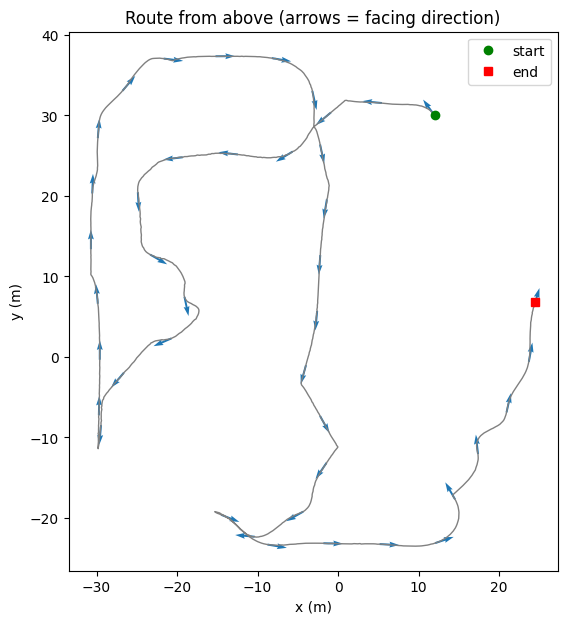

Next step is in front of the robot 100% of the time


In [7]:
import matplotlib.pyplot as plt

if positions_xy is not None:
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.plot(P[:, 0], P[:, 1], "-", lw=1, color="gray")
    k = max(1, N // 40)
    ax.quiver(P[::k, 0], P[::k, 1], np.cos(Y[::k]), np.sin(Y[::k]), color="tab:blue", scale=25, width=0.004)
    ax.plot(*P[0], "go", label="start"); ax.plot(*P[-1], "rs", label="end")
    ax.set_aspect("equal"); ax.legend(); ax.set_title("Route from above (arrows = facing direction)")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    plt.show()

    first_steps = np.array([to_local(P[t + 1], P[t], Y[t]) for t in range(N - 1)])
    forward_share = (first_steps[:, 0] > 0).mean()
    print(f"Next step is in front of the robot {100 * forward_share:.0f}% of the time")
    if forward_share < 0.7:
        print("WARNING: the robot often isn't moving forward. If this is an 'omni' route it may be driving")
        print("sideways; try a 'diff' route. If it's 'diff', the positions convention may be off; tell Claude.")

## 7. Prepare the images

ViNT works on very small images: each frame is center-cropped to a 4:3 shape and shrunk to 85×64 pixels, exactly as in its training.

In [8]:
from PIL import Image
import torchvision.transforms as T
import torchvision.transforms.functional as TF

normalize = T.Compose([T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def prep(path):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    img = TF.center_crop(img, (h, int(h * 4 / 3)) if w > h else (int(w * 3 / 4), w))
    return normalize(img.resize(IMAGE_SIZE))

frames = torch.stack([prep(frame_files[i]) for i in idx])   # [N, 3, 64, 85]
print("Prepared frames:", tuple(frames.shape))


@torch.no_grad()
def run_vint(pairs, batch_size=128):
    # pairs: list of (current used-frame index, goal used-frame index). Returns (distances, waypoints).
    dists, wps = [], []
    for b in range(0, len(pairs), batch_size):
        chunk = pairs[b: b + batch_size]
        obs = torch.stack([frames[t - CONTEXT_SIZE: t + 1].reshape(-1, *frames.shape[2:]) for t, _ in chunk])
        goal = torch.stack([frames[g] for _, g in chunk])
        d, a = model(obs.to(device), goal.to(device))
        dists.append(d.squeeze(-1).cpu()); wps.append(a.cpu())
    return torch.cat(dists).numpy(), torch.cat(wps).numpy()   # waypoints: [n, 5, (x, y, cos, sin)]

Prepared frames: (1151, 3, 64, 85)


### Turn check (do left and right match the photos?)

This finds the route's sharpest left turn and sharpest right turn according to the positions, and shows the camera view before and after. If the "left turn" photos actually show the robot turning right, set `FLIP_LEFT_RIGHT = True` in section 6 and re-run from there.

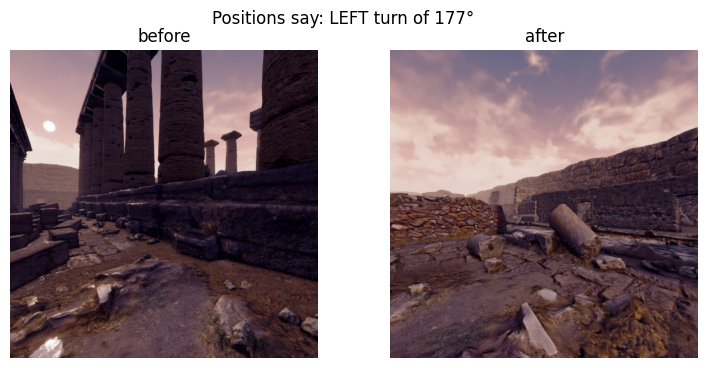

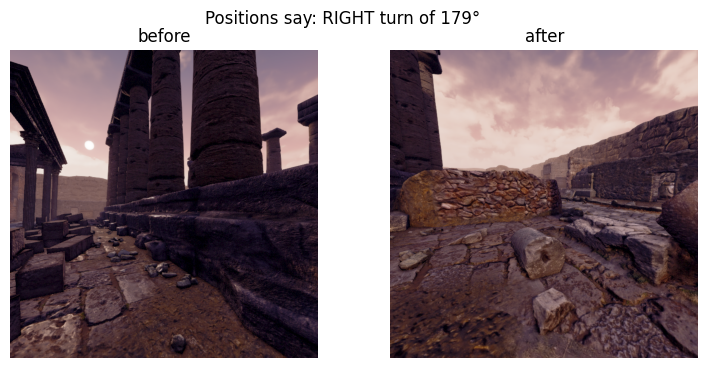

In [9]:
if positions_xy is not None:
    look = 8
    turn = np.array([np.degrees(np.angle(np.exp(1j * (Y[t + look] - Y[t])))) for t in range(N - look)])
    for name, t in [("LEFT turn", int(np.argmax(turn))), ("RIGHT turn", int(np.argmin(turn)))]:
        fig, axes = plt.subplots(1, 2, figsize=(9, 4))
        for ax, j, label in [(axes[0], t, "before"), (axes[1], t + look, "after")]:
            ax.imshow(Image.open(frame_files[idx[j]])); ax.axis("off"); ax.set_title(label)
        fig.suptitle(f"Positions say: {name} of {abs(turn[t]):.0f}°")
        plt.show()

## 8. Look at a single example

The 6 frames ViNT sees, the goal image, and its predicted path next to the real path.

Current photo: 000168_lcam_front.png
Goal photo:    000189_lcam_front.png
Goal is 2.3 m ahead along the route


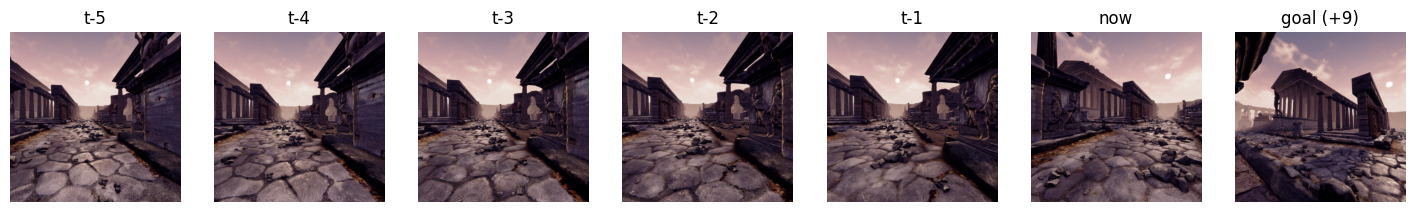

Predicted distance: 7.5   (true: 9)


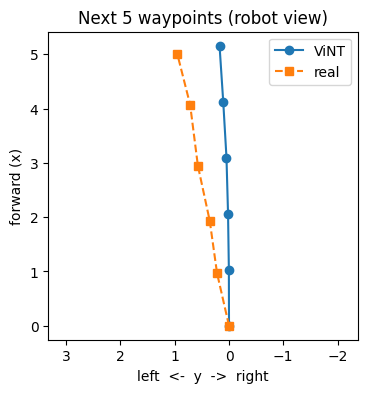

In [10]:
FRAME_NUMBER = 169   # <-- EDIT: the number in the photo's name, e.g. 000450_lcam_front.png
GOAL_AHEAD = 9       # <-- EDIT: how many used frames ahead the goal is (1-9 works best)

t = int(np.argmin(np.abs(idx - FRAME_NUMBER)))           # closest frame ViNT actually uses
t = max(CONTEXT_SIZE, min(t, N - 1 - max(GOAL_AHEAD, 5)))
k = GOAL_AHEAD
print("Current photo:", os.path.basename(frame_files[idx[t]]))
print("Goal photo:   ", os.path.basename(frame_files[idx[t + k]]))
if TRAVELED is not None:
    print(f"Goal is {path_length_m(t, t + k):.1f} m ahead along the route")

d, w = run_vint([(t, t + k)])

fig, axes = plt.subplots(1, CONTEXT_SIZE + 2, figsize=(18, 2.6))
for j in range(CONTEXT_SIZE + 1):
    axes[j].imshow(Image.open(frame_files[idx[t - CONTEXT_SIZE + j]])); axes[j].axis("off")
    axes[j].set_title("now" if j == CONTEXT_SIZE else f"t-{CONTEXT_SIZE - j}")
axes[-1].imshow(Image.open(frame_files[idx[t + k]])); axes[-1].axis("off"); axes[-1].set_title(f"goal (+{k})")
plt.show()

print(f"Predicted distance: {d[0]:.1f}   (true: {k})")
plt.figure(figsize=(4, 4))
plt.plot([0] + list(w[0, :, 1]), [0] + list(w[0, :, 0]), "o-", label="ViNT")
if positions_xy is not None:
    gt = true_waypoints(t)
    plt.plot([0] + list(gt[:, 1]), [0] + list(gt[:, 0]), "s--", label="real")
plt.gca().invert_xaxis(); plt.axis("equal"); plt.legend()
plt.xlabel("left  <-  y  ->  right"); plt.ylabel("forward (x)"); plt.title("Next 5 waypoints (robot view)")
plt.show()

## 9. Test 1: does predicted distance grow with real distance?

For many points along the route, the goal is set 1 to 20 frames ahead. A good result is a clear upward trend: close goals get small numbers, further goals get bigger ones.

Rank correlation (1.0 = perfect ordering, 0 = no relation): 0.54
Average error: 4.0 frames


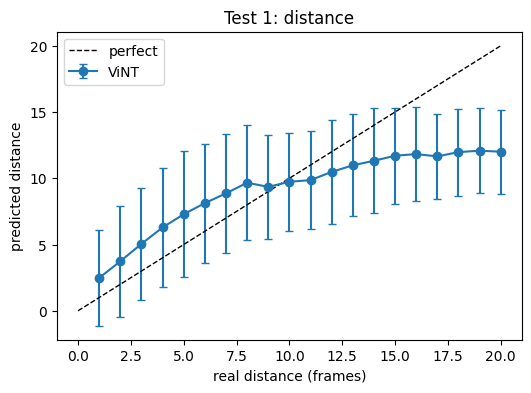

In [11]:
import pandas as pd
from scipy.stats import spearmanr

N_POSITIONS = 80     # how many points along the route to test
starts = np.linspace(CONTEXT_SIZE, N - 1 - MAX_DIST, N_POSITIONS).astype(int)
pairs = [(t, t + k) for t in starts for k in range(1, MAX_DIST + 1)]
pred_dist, _ = run_vint(pairs)
true_dist = np.array([g - t for t, g in pairs])

dist_df = pd.DataFrame({"current": [p[0] for p in pairs], "goal": [p[1] for p in pairs],
                        "true_distance": true_dist, "predicted_distance": pred_dist})
if TRAVELED is not None:
    dist_df["true_meters"] = [path_length_m(t, g) for t, g in pairs]
dist_df.to_csv(os.path.join(RESULTS_FOLDER, f"distance_test_{ENV}_{TRAJ}.csv"), index=False)

rho = spearmanr(true_dist, pred_dist).correlation
print(f"Rank correlation (1.0 = perfect ordering, 0 = no relation): {rho:.2f}")
print(f"Average error: {np.abs(pred_dist - true_dist).mean():.1f} frames")

summary = dist_df.groupby("true_distance")["predicted_distance"].agg(["mean", "std"])
plt.figure(figsize=(6, 4))
plt.errorbar(summary.index, summary["mean"], yerr=summary["std"], fmt="o-", capsize=3, label="ViNT")
plt.plot([0, MAX_DIST], [0, MAX_DIST], "k--", lw=1, label="perfect")
plt.xlabel("real distance (frames)"); plt.ylabel("predicted distance"); plt.legend()
plt.title("Test 1: distance"); plt.show()

## 10. Test 2: do the waypoints turn the right way?

ViNT was trained to steer toward goals 1 to 9 frames ahead, so this test uses goals 3 to 9 frames ahead. For each case we compare the direction of ViNT's 3rd waypoint (the one the official robot code drives toward) with where the robot really went.

Each direction is sorted into **left / straight / right** (more than 15° either way counts as a turn).

- Cases where the robot really moved more than `MAX_REAL_ANGLE` sideways or backwards are left out. A robot that only drives forward can't make those moves, so they'd unfairly count against ViNT.
- Turns are scored **separately** from straight driving. Most of a route is straight, so one overall percentage hides how well ViNT handles turns.

Cases: 1050   Left out as sideways/backwards: 0

Real left    :    7 cases   ViNT agreed  14%   median error 9°
Real right   :    7 cases   ViNT agreed   0%   median error 39°
Real straight: 1036 cases   ViNT agreed  98%   median error 2°

Turns only (left + right): ViNT agreed 7%   turned the WRONG way 0%


ViNT,left,right,straight
real,,,
left,1,0,6
right,0,0,7
straight,7,14,1015


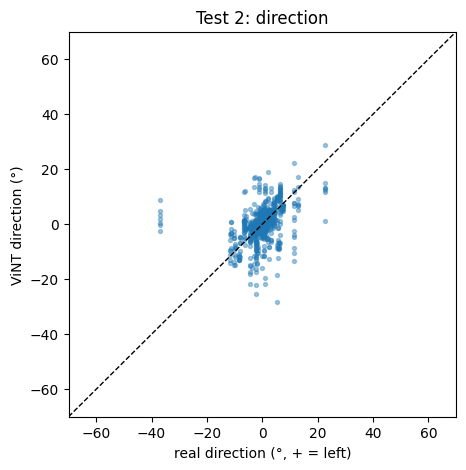

In [12]:
WAYPOINT = 2          # 0..4; 2 is what the official deployment code uses
TURN_DEG = 15         # more than this either way counts as a turn
MAX_REAL_ANGLE = 60   # leave out sideways/backwards moves beyond this

def direction_class(angle):
    return np.where(angle > TURN_DEG, "left", np.where(angle < -TURN_DEG, "right", "straight"))

if positions_xy is not None:
    starts = np.linspace(CONTEXT_SIZE, N - 1 - 9, 150).astype(int)
    pairs = [(t, t + k) for t in starts for k in range(3, 10)]
    _, pred_wp = run_vint(pairs)

    pred_angle = np.degrees(np.arctan2(pred_wp[:, WAYPOINT, 1], pred_wp[:, WAYPOINT, 0]))
    real_wp = np.array([true_waypoints(t)[WAYPOINT] for t, _ in pairs])
    real_angle = np.degrees(np.arctan2(real_wp[:, 1], real_wp[:, 0]))
    error = np.abs((pred_angle - real_angle + 180) % 360 - 180)

    dir_df = pd.DataFrame({"current": [p[0] for p in pairs], "goal": [p[1] for p in pairs],
                           "real_angle": real_angle, "predicted_angle": pred_angle, "error_deg": error,
                           "real_class": direction_class(real_angle), "predicted_class": direction_class(pred_angle)})
    dir_df["sideways_or_back"] = np.abs(real_angle) > MAX_REAL_ANGLE
    dir_df.to_csv(os.path.join(RESULTS_FOLDER, f"direction_test_{ENV}_{TRAJ}.csv"), index=False)

    scored = dir_df[~dir_df.sideways_or_back]
    print(f"Cases: {len(dir_df)}   Left out as sideways/backwards: {dir_df.sideways_or_back.sum()}")
    print()
    for cls in ["left", "right", "straight"]:
        sub = scored[scored.real_class == cls]
        if len(sub):
            hit = (sub.predicted_class == cls).mean()
            print(f"Real {cls:8s}: {len(sub):4d} cases   ViNT agreed {100 * hit:3.0f}%   "
                  f"median error {sub.error_deg.median():.0f}°")
        else:
            print(f"Real {cls:8s}:    0 cases")
    turns = scored[scored.real_class != "straight"]
    if len(turns):
        print(f"\nTurns only (left + right): ViNT agreed {100 * (turns.real_class == turns.predicted_class).mean():.0f}%   "
              f"turned the WRONG way {100 * ((turns.predicted_class != 'straight') & (turns.real_class != turns.predicted_class)).mean():.0f}%")
    display(pd.crosstab(scored.real_class, scored.predicted_class, rownames=["real"], colnames=["ViNT"]))

    plt.figure(figsize=(5, 5))
    plt.scatter(scored.real_angle, scored.predicted_angle, s=8, alpha=0.4)
    lim = MAX_REAL_ANGLE + 10
    plt.plot([-lim, lim], [-lim, lim], "k--", lw=1)
    plt.xlim(-lim, lim); plt.ylim(-lim, lim)
    plt.xlabel("real direction (°, + = left)"); plt.ylabel("ViNT direction (°)")
    plt.title("Test 2: direction"); plt.show()
else:
    print("Skipped: needs the positions file.")

## 11. Test 3: does ViNT notice when the goal is far away?

During training, goal images from unrelated places were labeled distance 20 ("not reachable from here"). This matters for your pipeline: it's how a robot could tell that a landmark image is **not** in reach, or that it has **arrived** at a hop.

- **Near goals:** 1 to 5 frames ahead.
- **Far goals:** at least `FAR_GAP` frames away along the route **and** at least `FAR_MIN_M` meters away in a straight line. The second rule removes spots where the route loops back past the same place, which would look close to ViNT and wrongly count as mistakes.

Average predicted distance, NEAR goals (1-5 ahead): 5.1
Average predicted distance, FAR goals:              14.2   (max possible 20)
Near goals scored below 10: 83%    Far goals scored above 10: 91%


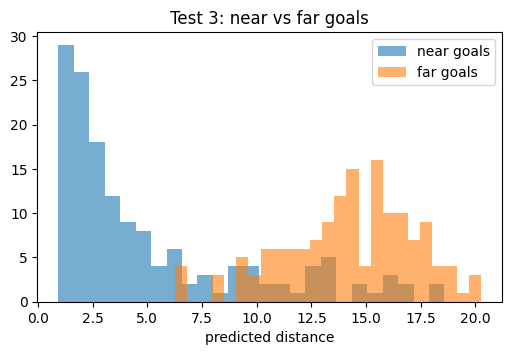

In [13]:
FAR_GAP = 80       # frames apart along the route
FAR_MIN_M = 15     # and at least this many meters apart in a straight line
rng = np.random.default_rng(0)

near_pairs, far_pairs = [], []
for t in np.linspace(CONTEXT_SIZE, N - 1 - 5, 150).astype(int):
    near_pairs.append((t, t + int(rng.integers(1, 6))))
    far_choices = [g for g in range(N) if abs(g - t) >= FAR_GAP
                   and (positions_xy is None or np.linalg.norm(P[g] - P[t]) >= FAR_MIN_M)]
    if far_choices:
        far_pairs.append((t, int(rng.choice(far_choices))))

if far_pairs:
    near_d, _ = run_vint(near_pairs)
    far_d, _ = run_vint(far_pairs)
    print(f"Average predicted distance, NEAR goals (1-5 ahead): {near_d.mean():.1f}")
    print(f"Average predicted distance, FAR goals:              {far_d.mean():.1f}   (max possible {MAX_DIST})")
    cut = MAX_DIST / 2
    print(f"Near goals scored below {cut:.0f}: {100 * (near_d < cut).mean():.0f}%    "
          f"Far goals scored above {cut:.0f}: {100 * (far_d > cut).mean():.0f}%")

    plt.figure(figsize=(6, 3.5))
    plt.hist(near_d, bins=25, alpha=0.6, label="near goals")
    plt.hist(far_d, bins=25, alpha=0.6, label="far goals")
    plt.xlabel("predicted distance"); plt.legend(); plt.title("Test 3: near vs far goals"); plt.show()

    pd.DataFrame({"type": ["near"] * len(near_d) + ["far"] * len(far_d),
                  "current": [p[0] for p in near_pairs + far_pairs],
                  "goal": [p[1] for p in near_pairs + far_pairs],
                  "predicted_distance": np.r_[near_d, far_d]}
                 ).to_csv(os.path.join(RESULTS_FOLDER, f"far_goal_test_{ENV}_{TRAJ}.csv"), index=False)
else:
    print(f"Route too short or too compact for far goals; lower FAR_GAP ({FAR_GAP}) or FAR_MIN_M ({FAR_MIN_M}).")

## 12. What to write down

| What | Where |
|---|---|
| Distance rank correlation and average error | Section 9 |
| Agreement for real left, right and straight cases (turns separately) | Section 10 |
| Wrong-way turns, and left out sideways/backwards cases | Section 10 |
| Near vs far average distance | Section 11 |
| Environment, robot type, route, frame spacing | Sections 4 and 6 |

Run it on 2 or 3 routes (and ideally 2 environments) before drawing conclusions. One route can be unusually easy or hard.